<a href="https://colab.research.google.com/github/claragarciaperez/Open_Quantum_Systems_RI/blob/main/qiskit_harmoscill.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install qiskit[visualization]
!pip install qiskit-aer
!pip install qiskit-ibm-runtime
!pip install pylatexenc
!pip install qiskit-bosons

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 800.8/800.8 kB 7.4 MB/s  0:00:00


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from qiskit import transpile, QuantumCircuit
from qiskit_aer import AerSimulator
import qiskit.quantum_info as qi
from qiskit.visualization import plot_histogram
from qiskit_ibm_runtime import QiskitRuntimeService
from google.colab import drive
from qiskit_aer.noise import (
    NoiseModel,
    QuantumError,
    ReadoutError,
    depolarizing_error,
    pauli_error,
    thermal_relaxation_error,
)
from qiskit.circuit.library import UnitaryGate
from qiskit.quantum_info import Operator,Pauli
from scipy.linalg import expm, svd
from qiskit_bosons.operators import BosonOperator, ann, cre
from qiskit_bosons.mappers import LevelSpec
from qiskit_bosons.mappers.library import occupation_encoding
from qiskit.quantum_info import SparsePauliOp
from scipy.linalg import expm, svd
from scipy.interpolate import interp1d


drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
def n_op():
  n = BosonOperator.from_dict({
    (cre(0), ann(0)): 1.0
})
  spec = LevelSpec(3, "gray")
#spec = LevelSpec(3, "standard_binary")


  n_gray = occupation_encoding(n, spec)

  n_pauli = SparsePauliOp.from_sparse_observable(n_gray).simplify()
  return n_pauli.to_matrix()

def a_dagger():
  cre_op = BosonOperator.from_dict({
    (cre(0),): 1.0
})
  spec = LevelSpec(3, "gray")
  #spec = LevelSpec(3, "standard=
  cre_gray = occupation_encoding(cre_op, spec)
  cre_pauli = SparsePauliOp.from_sparse_observable(cre_gray).simplify()
  return cre_pauli.to_matrix()

def a():
  ann_op = BosonOperator.from_dict({
    (ann(0),): 1.0
})
  spec = LevelSpec(3, "gray")
  #spec = LevelSpec(3, "standard_binary")
  ann_gray = occupation_encoding(ann_op, spec)
  ann_pauli = SparsePauliOp.from_sparse_observable(ann_gray).simplify()
  return ann_pauli.to_matrix()


In [ ]:

def harmosc_adaggera(simulator_aer, N = 25, g = 0.7, l= 0.2,delta_t = 0.5, T = 0, omega_A = 0.5, omegah = 0.5, nshots = 1024, bosonic = False):
  p_x= Pauli('X').to_matrix()
  p_y = Pauli('Y').to_matrix()

  # We change the sign because of how the basis is chosen
  splus = (1/2)*(p_x-1j*p_y)
  sminus = (1/2)*(p_x+1j*p_y)



  sz_01_nonoise = []
  sz_1_nonoise = []




  if T !=0:
    beta = 1/T
    alpha = 2*np.acos(np.sqrt(1/(1+np.exp(-beta*omega_A))))
    if bosonic==True:
      n_B = 1/(np.exp(omega_A/T)-1)
      g = g*np.sqrt(2*n_B+ 1)
      V = g*(np.kron(sminus,a_dagger()) +
       np.kron(splus,a()))
      U1 = expm(-1j*V*delta_t)
      U_gate = UnitaryGate(U1, label="U")
    for niter in range(0,N+1):
      qc = QuantumCircuit(4,2)
      qc.ry(alpha,2)
      qc.cx(2,3)
      for i in range(0,niter):
        qc.rzz(-omegah*delta_t,0,1)
        qc.rz(-omegah*2*delta_t,1)

        qc.rz(-omega_A*delta_t,2)

        qc.append(U_gate, [0,1,2])

        qc.reset(2)
        qc.reset(3)
        qc.ry(alpha,2)
        qc.cx(2,3)
      qc.measure(0,0)
      qc.measure(1,1)
      job = simulator_aer.run(qc,shots = nshots)
      results = job.result().get_counts()
      sz_01 = 0
      sz_1 = 0

      for bitstring, count in results.items():

          sz_01 += (1 if bitstring in ['00', '11'] else -1) * count

          sz_1 += (1 if bitstring[-2] == '0' else -1) * count

      sz_01 /= nshots
      sz_1 /= nshots

      sz_01_nonoise.append(sz_01)
      sz_1_nonoise.append(sz_1)
  else:
    V = g*(np.kron(sminus,a_dagger()) +
       np.kron(splus,a()))

    U1 = expm(-1j*V*delta_t)
    U_gate = UnitaryGate(U1, label="U")
    for niter in range(0,N+1):
      qc = QuantumCircuit(3,2)
      for i in range(0,niter):
        qc.rzz(-omegah*delta_t,0,1)
        qc.rz(omegah*2*delta_t,1)

        qc.rz(-omega_A*delta_t,2)

        qc.append(U_gate, [0,1,2])

        qc.reset(2)
      qc.measure(0,0)
      qc.measure(1,1)
      job = simulator_aer.run(qc,shots = nshots)
      results = job.result().get_counts()
      sz_01 = 0
      sz_1 = 0
      for bitstring, count in results.items():

          sz_01 += (1 if bitstring in ['00', '11'] else -1) * count

          sz_1 += (1 if bitstring[-2] == '0' else -1) * count

      sz_01 /= nshots
      sz_1 /= nshots

      sz_01_nonoise.append(sz_01)
      sz_1_nonoise.append(sz_1)
  return sz_01_nonoise, sz_1_nonoise

0
0.1
0.25
0.5
1


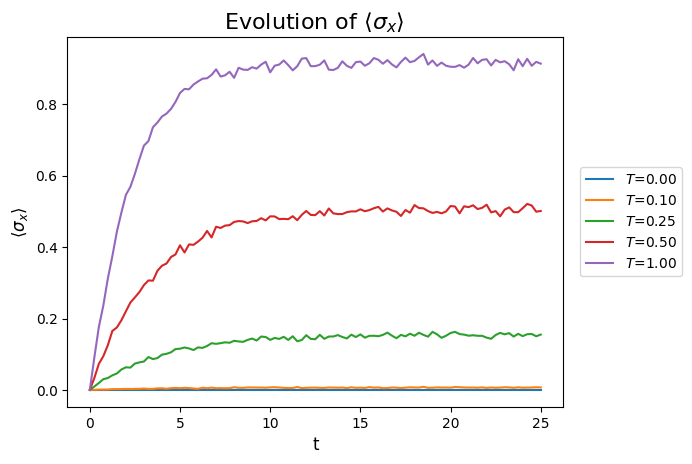

In [ ]:
simulator_aer = AerSimulator()
Gamma = 0.25
delta_t = 0.25
g = np.sqrt(Gamma/delta_t)
N = int(25/delta_t)
omega_A = 0.5
nshots = 8192
omegah = 0.5
time = np.arange(N+1) * delta_t

fig_x, ax_x = plt.subplots()

for T in [0,0.1,0.25,0.5,1]:
  print(T)
  n = []
  s01,s1  = harmosc_adaggera(simulator_aer= simulator_aer,  g=g, N = N, delta_t = delta_t, T = T, omega_A=omega_A, omegah=omegah,bosonic = True, nshots = nshots)
  #Conversion of n given our gray encoding
  for i in range(len(time)):
    n.append(1.5 - s1[i]-s01[i]/2 )

  ax_x.plot(time, n, label=rf'$T$={T:.2f}')

  datos = np.column_stack((time, n))

  np.savetxt(
    f"/content/drive/MyDrive/qiskit_harmosc_bosonicbath_ns{nshots}_nonoise_omegah_{omegah:.2f}_omegaA_{omega_A:.2f}_deltat_{delta_t:.2f}_T_{T:.2f}.txt",
    datos,
    header="t n",
    fmt="%.10f"
    )


ax_x.set_xlabel('t', fontsize = 12)
ax_x.set_ylabel(r'$\langle \sigma_x \rangle$', fontsize = 12)
ax_x.set_title(rf'Evolution of $\langle \sigma_x \rangle$ ', fontsize = 16)
ax_x.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))


plt.show()




# Compare with Lindblad Solution

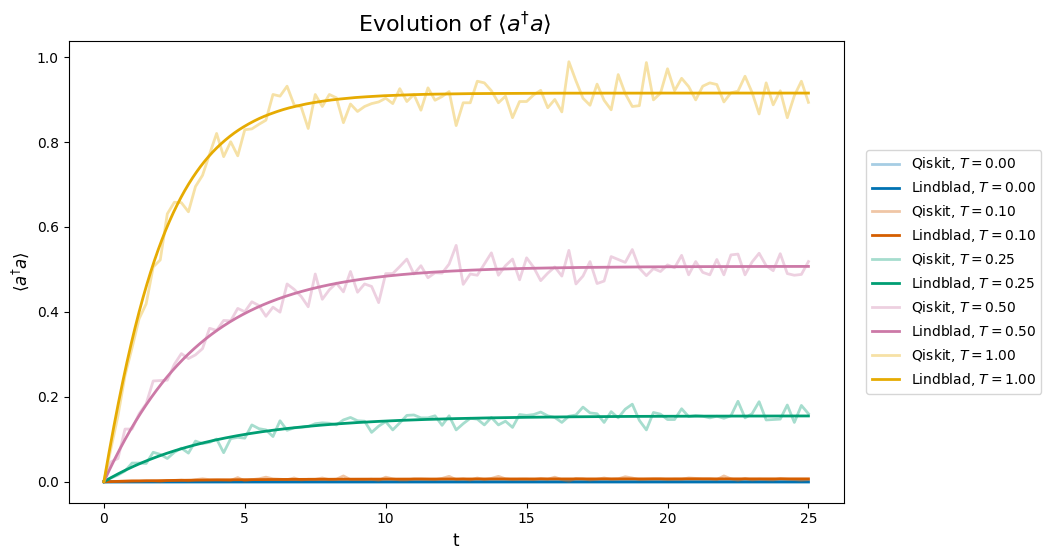

In [ ]:
Gamma = 0.25
delta_t = 0.25
g = np.sqrt(Gamma/delta_t)
omega = 0.5
N = int(25/delta_t)
omega_A = omega
nshots = 1024
omegah = 0.5



Ts = [0, 0.1, 0.25, 0.5, 1]

colors = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E6AB02']



fig_x, ax_x = plt.subplots(figsize=(10, 6))


for T, color in zip(Ts, colors):

    filename = (
        f"/content/drive/MyDrive/qiskit_harmosc_bosonicbath_ns{nshots}_nonoise_omegah_{omegah:.2f}_omegaA_{omega_A:.2f}_deltat_{delta_t:.2f}_T_{T:.2f}.txt"
    )

    file2 = (
        f"/content/drive/MyDrive/linblad_harmosc_omegah_{omegah:.2f}_omegaA_{omega_A:.2f}_Gamma_{Gamma:.2f}_T_{T:.2f}.txt"
    )

    datos = np.loadtxt(filename, skiprows=1)
    datos2 = np.loadtxt(file2, skiprows=1)

    time = datos[:, 0]
    n_qiskit = datos[:, 1]


    time2 = datos2[:, 0]
    n_lindblad = datos2[:, 1]

    ax_x.plot(time, n_qiskit, color=color, linestyle='-',
              linewidth=2,alpha=0.35,
              label=rf'Qiskit, $T={T:.2f}$' )

    ax_x.plot(time2, n_lindblad, color=color, linestyle='-',
              linewidth=2, alpha=1,
              label=rf'Lindblad, $T={T:.2f}$')



ax_x.set_xlabel('t', fontsize=12)
ax_x.set_ylabel(r'$\langle a^{\dagger}a \rangle$', fontsize=12)
ax_x.set_title(r'Evolution of $\langle a^{\dagger}a \rangle$ ', fontsize=16)
ax_x.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))



plt.show()

## Calculate the error with respect to lindblad

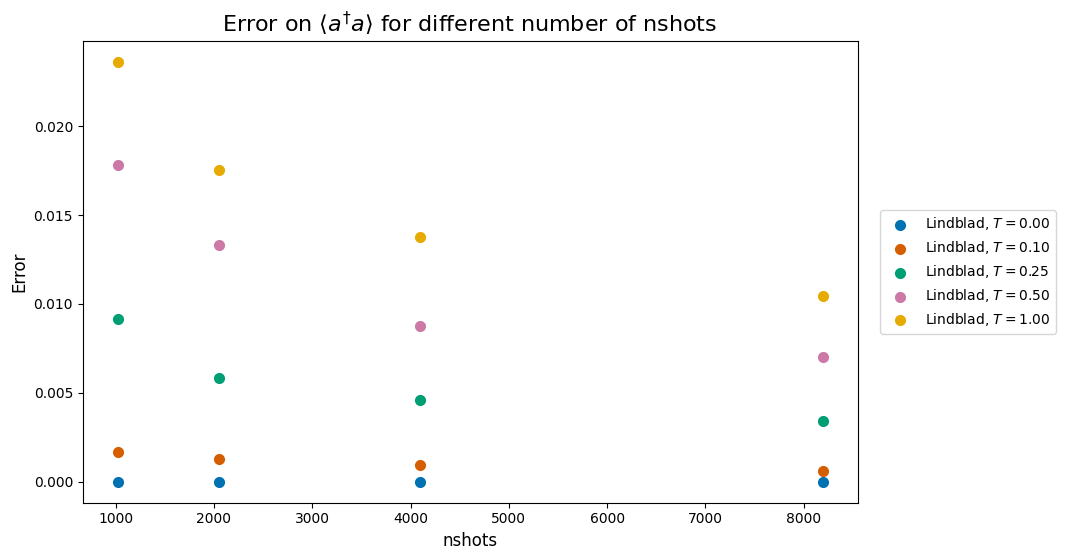

In [ ]:

Gamma = 0.25
delta_t = 0.25
g = np.sqrt(Gamma/delta_t)
omega = 0.5
N = int(25/delta_t)
omega_A = omega
omegah = 0.5



Ts = [0, 0.1, 0.25, 0.5, 1]
nshots_list = [1024, 2048, 4096,8192]

colors = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E6AB02']



fig_x, ax_x = plt.subplots(figsize=(10, 6))


for T, color in zip(Ts, colors):
  total_error_n = []
  for n_shots in nshots_list:
    nshots = n_shots

    filename = (
        f"/content/drive/MyDrive/qiskit_harmosc_bosonicbath_ns{nshots}_nonoise_omegah_{omegah:.2f}_omegaA_{omega_A:.2f}_deltat_{delta_t:.2f}_T_{T:.2f}.txt"
    )

    file2 = (
        f"/content/drive/MyDrive/linblad_harmosc_omegah_{omegah:.2f}_omegaA_{omega_A:.2f}_Gamma_{Gamma:.2f}_T_{T:.2f}.txt"
    )

    datos = np.loadtxt(filename, skiprows=1)
    datos2 = np.loadtxt(file2, skiprows=1)

    # Qiskit
    time = datos[:, 0]
    n_qiskit = datos[:, 1]


    # Lindblad
    time2 = datos2[:, 0]
    n_lindblad = datos2[:, 1]

    n_lindblad_interp = interp1d(
    time2, n_lindblad, kind='linear',
    bounds_error=False, fill_value=np.nan
    )

    n_lindblad_near = n_lindblad_interp(time)
    error_n = np.abs(n_qiskit - n_lindblad_near)
    total_error_n.append(np.mean(error_n))


  ax_x.scatter(nshots_list, total_error_n, color=color,
            linewidth=2, alpha=1,
            label=rf'Lindblad, $T={T:.2f}$')




ax_x.set_xlabel('nshots', fontsize=12)
ax_x.set_ylabel(r'Error', fontsize=12)
ax_x.set_title(r'Error on $\langle a^{\dagger}a\rangle$ for different number of nshots ', fontsize=16)
ax_x.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))



plt.show()